In [37]:

import pandas as pd
import numpy as np

# Make the results reproducible
np.random.seed(42)

# Number of simulated customers
n = 500

# Generate customer ages
age = np.random.randint(18, 61, n)

# Generate preferred product categories
categories = ["Skincare", "Haircare", "Makeup", "Wellness"]

product_category = np.random.choice(
    categories,
    size=n,
    p=[0.40, 0.25, 0.20, 0.15]
)

# Generate purchasing behavior
purchase_frequency = np.random.randint(1, 13, n)

category_prices = {
    "Skincare": 850,
    "Haircare": 650,
    "Makeup": 1100,
    "Wellness": 950
}

purchase_amount = [
    max(100, np.random.normal(category_prices[c], 200))
    for c in product_category
]

# Generate ratings between 1 and 5
rating = np.round(np.random.uniform(2.5, 5.0, n), 1)

# Generate discount usage percentage
discount_used = np.random.choice(
    [0, 5, 10, 15, 20],
    size=n
)

# Generate browsing time in minutes
browsing_time = np.random.randint(1, 31, n)

# Simulate repeat-purchase behavior
repeat_probability = (
    0.15
    + 0.04 * purchase_frequency
    + 0.10 * (rating - 3)
)

repeat_probability = np.clip(repeat_probability, 0.05, 0.95)

repeat_purchase = np.where(
    np.random.random(n) < repeat_probability,
    "Yes",
    "No"
)

# Create the dataset
df = pd.DataFrame({
    "Customer_ID": [f"C{i:04d}" for i in range(1, n + 1)],
    "Age": age,
    "Product_Category": product_category,
    "Purchase_Frequency": purchase_frequency,
    "Purchase_Amount": np.round(purchase_amount, 2),
    "Rating": rating,
    "Discount_Used": discount_used,
    "Browsing_Time": browsing_time,
    "Repeat_Purchase": repeat_purchase
})

# Save and display the dataset
df.to_csv("beauty_customers.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))


Dataset created successfully!
Dataset shape: (500, 9)


,Customer_ID,Age,Product_Category,Purchase_Frequency,Purchase_Amount,Rating,Discount_Used,Browsing_Time,Repeat_Purchase
0,C0001,56,Skincare,11,936.17,3.2,5,26,Yes
1,C0002,46,Makeup,4,1148.66,4.8,20,8,No
2,C0003,32,Skincare,4,781.26,4.2,0,9,No
3,C0004,60,Wellness,5,1259.84,3.7,5,23,Yes
4,C0005,25,Wellness,6,726.68,2.5,5,5,Yes
5,C0006,38,Haircare,5,415.73,5.0,10,24,No
6,C0007,56,Makeup,7,1288.43,4.2,10,20,No
7,C0008,36,Makeup,2,1272.02,3.3,20,18,No
8,C0009,40,Skincare,7,920.75,4.7,5,11,No
9,C0010,28,Wellness,10,892.41,3.1,5,15,Yes


In [38]:

# STEP 3: DATA INSPECTION

print("1. Dataset size (rows, columns):")
print(df.shape)

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. Data types and non-empty values:")
df.info()

print("\n4. Missing values in each column:")
print(df.isnull().sum())

print("\n5. Number of duplicate rows:")
print(df.duplicated().sum())

print("\n6. Summary of numerical columns:")
display(df.select_dtypes(include="number").describe())

print("\n7. Customers by product category:")
print(df["Product_Category"].value_counts())

print("\n8. Repeat purchase distribution:")
print(df["Repeat_Purchase"].value_counts())


1. Dataset size (rows, columns):
(500, 9)

2. Column names:
['Customer_ID', 'Age', 'Product_Category', 'Purchase_Frequency', 'Purchase_Amount', 'Rating', 'Discount_Used', 'Browsing_Time', 'Repeat_Purchase']

3. Data types and non-empty values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         500 non-null    object 
 1   Age                 500 non-null    int64  
 2   Product_Category    500 non-null    object 
 3   Purchase_Frequency  500 non-null    int64  
 4   Purchase_Amount     500 non-null    float64
 5   Rating              500 non-null    float64
 6   Discount_Used       500 non-null    int64  
 7   Browsing_Time       500 non-null    int64  
 8   Repeat_Purchase     500 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 35.3+ KB

4. Missing values in each column:
Customer_ID    

,Age,Purchase_Frequency,Purchase_Amount,Rating,Discount_Used,Browsing_Time
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000
mean,39.506000,6.544000,868.186020,3.743400,10.280000,15.84600
std,12.368505,3.502656,262.663215,0.735948,7.114973,8.63269
min,18.000000,1.000000,146.990000,2.500000,0.000000,1.00000
25%,29.000000,3.000000,697.337500,3.100000,5.000000,8.00000
50%,41.000000,7.000000,869.830000,3.700000,10.000000,16.00000
75%,50.000000,10.000000,1046.562500,4.400000,15.000000,23.00000
max,60.000000,12.000000,1593.150000,5.000000,20.000000,30.00000



7. Customers by product category:
Product_Category
Skincare    207
Haircare    128
Makeup       84
Wellness     81
Name: count, dtype: int64

8. Repeat purchase distribution:
Repeat_Purchase
No     280
Yes    220
Name: count, dtype: int64


In [39]:

# STEP 3B: DATA CLEANING

# Remove duplicate records
df = df.drop_duplicates()

# Ensure numerical columns contain numeric values
numeric_columns = [
    "Age",
    "Purchase_Frequency",
    "Purchase_Amount",
    "Rating",
    "Discount_Used",
    "Browsing_Time"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Check for missing values after conversion
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check whether numerical values are within expected ranges
print("\nAge range:", df["Age"].min(), "-", df["Age"].max())
print("Rating range:", df["Rating"].min(), "-", df["Rating"].max())
print("Purchase amount minimum:", df["Purchase_Amount"].min())

print("\nDataset size after cleaning:", df.shape)
print("Data cleaning completed!")


Missing values after cleaning:
Customer_ID           0
Age                   0
Product_Category      0
Purchase_Frequency    0
Purchase_Amount       0
Rating                0
Discount_Used         0
Browsing_Time         0
Repeat_Purchase       0
dtype: int64

Age range: 18 - 60
Rating range: 2.5 - 5.0
Purchase amount minimum: 146.99

Dataset size after cleaning: (500, 9)
Data cleaning completed!


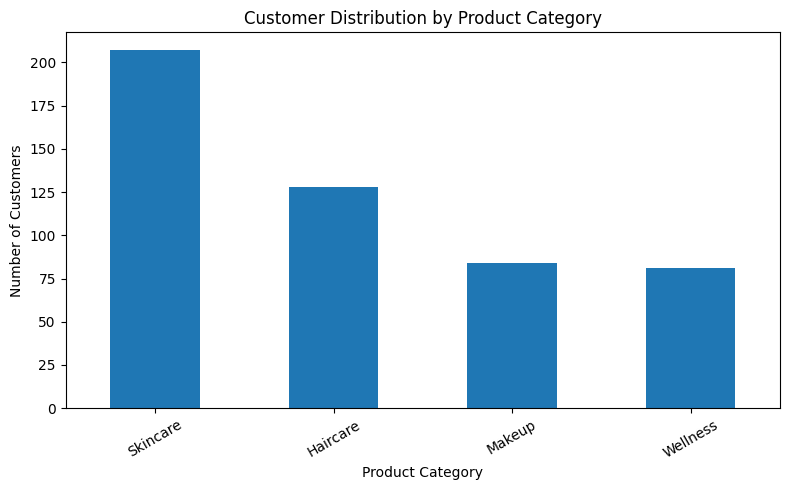

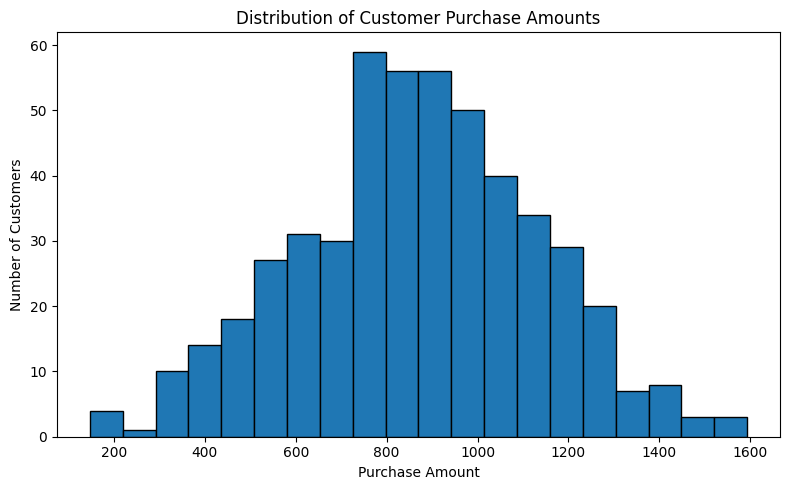

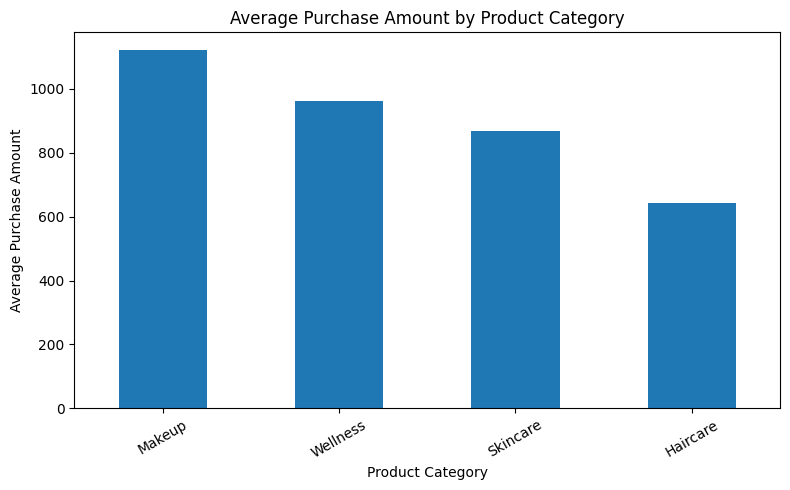

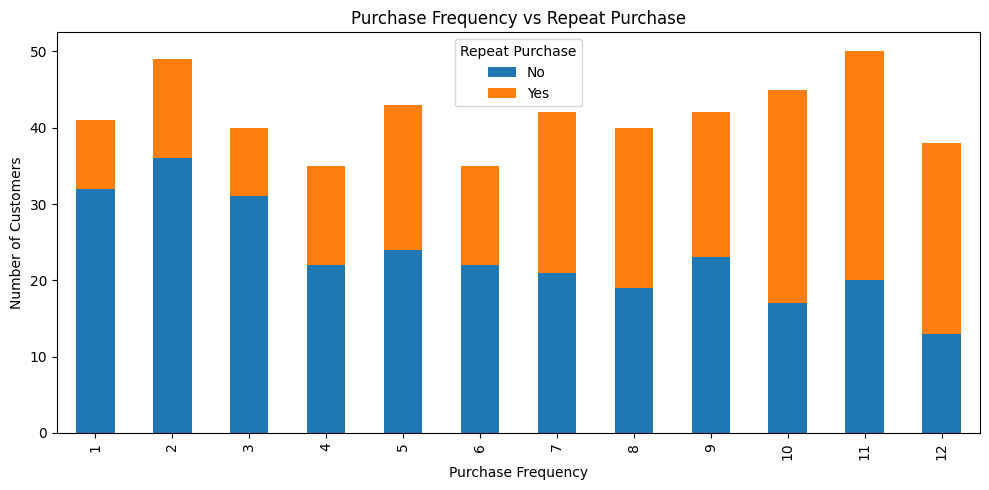

EDA charts generated successfully!


In [40]:

# STEP 4: EXPLORATORY DATA ANALYSIS (EDA)

import matplotlib.pyplot as plt
import pandas as pd

# Chart 1: Number of customers in each product category
category_counts = df["Product_Category"].value_counts()

plt.figure(figsize=(8, 5))
category_counts.plot(kind="bar")
plt.title("Customer Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 2: Purchase amount distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Purchase_Amount"], bins=20, edgecolor="black")
plt.title("Distribution of Customer Purchase Amounts")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# Chart 3: Average purchase amount by product category
average_spending = df.groupby("Product_Category")[
    "Purchase_Amount"
].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
average_spending.plot(kind="bar")
plt.title("Average Purchase Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 4: Purchase frequency and repeat purchase
repeat_counts = pd.crosstab(
    df["Purchase_Frequency"],
    df["Repeat_Purchase"]
)

repeat_counts.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Purchase Frequency vs Repeat Purchase")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.legend(title="Repeat Purchase")
plt.tight_layout()
plt.show()

print("EDA charts generated successfully!")


In [41]:

# KEY FINDINGS FROM THE DATA

print("Total customers:", len(df))

print("\nCustomer count by product category:")
print(df["Product_Category"].value_counts())

print("\nAverage purchase amount by category:")
print(
    df.groupby("Product_Category")["Purchase_Amount"]
    .mean()
    .round(2)
)

print("\nOverall average purchase amount:")
print(round(df["Purchase_Amount"].mean(), 2))

print("\nAverage purchase frequency:")
print(round(df["Purchase_Frequency"].mean(), 2))

print("\nRepeat purchase percentage:")
repeat_percentage = (
    df["Repeat_Purchase"].eq("Yes").mean() * 100
)
print(round(repeat_percentage, 2), "%")

print("\nAverage rating:")
print(round(df["Rating"].mean(), 2), "/ 5")


Total customers: 500

Customer count by product category:
Product_Category
Skincare    207
Haircare    128
Makeup       84
Wellness     81
Name: count, dtype: int64

Average purchase amount by category:
Product_Category
Haircare     643.01
Makeup      1121.34
Skincare     867.73
Wellness     962.64
Name: Purchase_Amount, dtype: float64

Overall average purchase amount:
868.19

Average purchase frequency:
6.54

Repeat purchase percentage:
44.0 %

Average rating:
3.74 / 5


CUSTOMER SEGMENT SUMMARY


,Age,Purchase_Frequency,Purchase_Amount,Browsing_Time
Customer_Segment,,,,
0,26.16,6.67,797.73,18.52
1,47.31,9.43,823.77,12.47
2,45.48,3.21,994.68,16.65


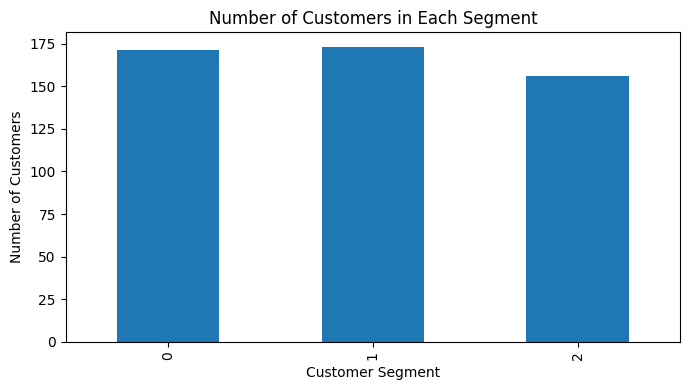

In [42]:

# STEP 5A: CUSTOMER SEGMENTATION USING K-MEANS

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd

# Select customer behaviour features
segment_features = [
    "Age",
    "Purchase_Frequency",
    "Purchase_Amount",
    "Browsing_Time"
]

X_segment = df[segment_features].copy()

# Scale the features so large values don't dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_segment)

# Create 3 customer segments
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Customer_Segment"] = kmeans.fit_predict(X_scaled)

# View the average characteristics of each segment
segment_summary = df.groupby("Customer_Segment")[
    segment_features
].mean().round(2)

print("CUSTOMER SEGMENT SUMMARY")
display(segment_summary)

# Visualise the number of customers in each segment
df["Customer_Segment"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


PRODUCT PREFERENCE PREDICTION RESULTS
Test accuracy: 47.00%

Classification report:
              precision    recall  f1-score   support

    Haircare       0.55      0.46      0.50        26
      Makeup       0.32      0.35      0.33        17
    Skincare       0.52      0.66      0.58        41
    Wellness       0.29      0.12      0.17        16

    accuracy                           0.47       100
   macro avg       0.42      0.40      0.40       100
weighted avg       0.45      0.47      0.45       100



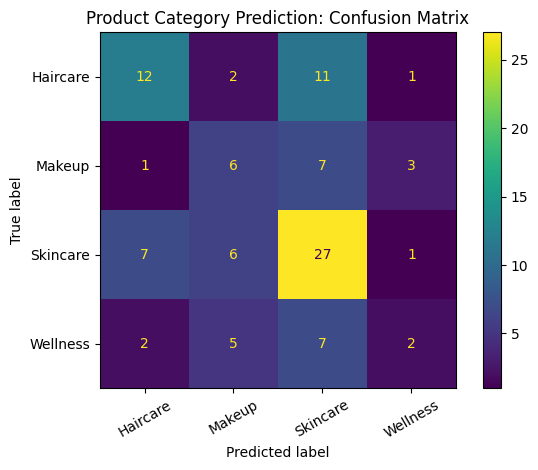

In [43]:

# STEP 5B: PRODUCT PREFERENCE PREDICTION

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Input features: do not include Product_Category itself
feature_columns = [
    "Age",
    "Purchase_Frequency",
    "Purchase_Amount",
    "Rating",
    "Discount_Used",
    "Browsing_Time",
    "Repeat_Purchase"
]

X = df[feature_columns].copy()
y = df["Product_Category"]

# Convert the Yes/No column into numeric indicator columns
X = pd.get_dummies(X, columns=["Repeat_Purchase"], dtype=int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train the Decision Tree
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

# Predict categories for test customers
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("PRODUCT PREFERENCE PREDICTION RESULTS")
print(f"Test accuracy: {accuracy:.2%}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=30
)

plt.title("Product Category Prediction: Confusion Matrix")
plt.tight_layout()
plt.show()


In [44]:

# DEMO: PREDICT A PRODUCT CATEGORY FOR A SAMPLE CUSTOMER

sample_customer = pd.DataFrame([{
    "Age": 25,
    "Purchase_Frequency": 6,
    "Purchase_Amount": 900,
    "Rating": 4.2,
    "Discount_Used": 10,
    "Browsing_Time": 15,
    "Repeat_Purchase": "Yes"
}])

# Apply the same encoding as the training data
sample_encoded = pd.get_dummies(
    sample_customer,
    columns=["Repeat_Purchase"],
    dtype=int
)

# Ensure the sample has exactly the model's input columns
sample_encoded = sample_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

predicted_category = model.predict(sample_encoded)[0]

print("Sample customer details:")
display(sample_customer)

print("Predicted product category:", predicted_category)
print("Note: This is a demonstration using simulated data.")


Sample customer details:


,Age,Purchase_Frequency,Purchase_Amount,Rating,Discount_Used,Browsing_Time,Repeat_Purchase
0,25,6,900,4.2,10,15,Yes


Predicted product category: Skincare
Note: This is a demonstration using simulated data.


In [45]:

# STEP 6A: COLLECT PROJECT FINDINGS

findings = []

findings.append("BEAUTY & WELLNESS CUSTOMER ANALYTICS")
findings.append("Dataset: Simulated demonstration data")
findings.append(f"Total customer records: {len(df)}")
findings.append(f"Total columns: {len(df.columns)}")

findings.append("\n1. PRODUCT CATEGORY COUNTS")
findings.append(df["Product_Category"].value_counts().to_string())

findings.append("\n2. AVERAGE PURCHASE AMOUNT BY CATEGORY")
findings.append(
    df.groupby("Product_Category")["Purchase_Amount"]
    .mean().round(2).to_string()
)

findings.append("\n3. OVERALL STATISTICS")
findings.append(
    f"Average purchase amount: {df['Purchase_Amount'].mean():.2f}"
)
findings.append(
    f"Average purchase frequency: {df['Purchase_Frequency'].mean():.2f}"
)
findings.append(
    f"Repeat purchase percentage: "
    f"{df['Repeat_Purchase'].eq('Yes').mean() * 100:.2f}%"
)
findings.append(f"Average rating: {df['Rating'].mean():.2f}/5")

findings.append("\n4. CUSTOMER SEGMENT SIZES")
findings.append(
    df["Customer_Segment"].value_counts().sort_index().to_string()
)

findings.append("\n5. CUSTOMER SEGMENT PROFILES")
findings.append(
    df.groupby("Customer_Segment")[
        ["Age", "Purchase_Frequency", "Purchase_Amount", "Browsing_Time"]
    ].mean().round(2).to_string()
)

findings.append(f"\n6. DECISION TREE TEST ACCURACY: {accuracy:.2%}")

findings.append(
    "\nIMPORTANT: These are simulated data results for demonstration. "
    "They should not be interpreted as real industry findings."
)

report_text = "\n".join(findings)

print(report_text)

with open("final_findings.txt", "w", encoding="utf-8") as file:
    file.write(report_text)

print("\nFindings saved to final_findings.txt")


BEAUTY & WELLNESS CUSTOMER ANALYTICS
Dataset: Simulated demonstration data
Total customer records: 500
Total columns: 10

1. PRODUCT CATEGORY COUNTS
Product_Category
Skincare    207
Haircare    128
Makeup       84
Wellness     81

2. AVERAGE PURCHASE AMOUNT BY CATEGORY
Product_Category
Haircare     643.01
Makeup      1121.34
Skincare     867.73
Wellness     962.64

3. OVERALL STATISTICS
Average purchase amount: 868.19
Average purchase frequency: 6.54
Repeat purchase percentage: 44.00%
Average rating: 3.74/5

4. CUSTOMER SEGMENT SIZES
Customer_Segment
0    171
1    173
2    156

5. CUSTOMER SEGMENT PROFILES
                    Age  Purchase_Frequency  Purchase_Amount  Browsing_Time
Customer_Segment                                                           
0                 26.16                6.67           797.73          18.52
1                 47.31                9.43           823.77          12.47
2                 45.48                3.21           994.68          16.65

6. DE

In [46]:
from google.colab import files
files.download("final_findings.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

!pip -q install python-docx

from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION

doc = Document()

# Page layout
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Professional typography
styles = doc.styles
styles["Normal"].font.name = "Calibri"
styles["Normal"].font.size = Pt(10)
styles["Title"].font.name = "Calibri"
styles["Title"].font.size = Pt(25)
styles["Title"].font.bold = True
styles["Heading 1"].font.color.rgb = RGBColor(31, 78, 121)

def heading(text, level=1):
    doc.add_heading(text, level=level)

def paragraph(text):
    doc.add_paragraph(text)

def bullet(text):
    doc.add_paragraph(text, style="List Bullet")

# Cover page
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run("\n\n\n")
title = doc.add_paragraph(style="Title")
title.alignment = WD_ALIGN_PARAGRAPH.CENTER
title.add_run(
    "Data-Driven Customer Segmentation and\n"
    "Product Preference Prediction"
)

subtitle = doc.add_paragraph()
subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER
subtitle.add_run(
    "A Data Science Proposal for the Beauty & Wellness Industry"
).bold = True

paragraph("\n")
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run("Internship Project Report\n")
p.add_run("Prepared by: [Enter Your Full Name]\n")
p.add_run("Date: 11 October 2026")
doc.add_page_break()

# 1. Abstract
heading("Abstract")
paragraph(
    "This project explores how data science can support customer "
    "segmentation and product preference analysis in the beauty and "
    "wellness industry. It presents a proposed analytical framework "
    "using customer characteristics, purchase behaviour, spending, "
    "ratings, discount use and browsing time. A simulated dataset of "
    f"{len(df)} customer records was used to demonstrate data inspection, "
    "cleaning, exploratory data analysis, K-Means clustering and "
    "Decision Tree classification. The work illustrates a practical "
    "analytics workflow rather than establishing validated conclusions "
    "about real consumers. Results are interpreted as demonstrations "
    "because the dataset was synthetically generated. The report discusses "
    "research questions, hypotheses, methodological choices, potential "
    "marketing applications, limitations and future validation using "
    "authentic, consented customer data."
)

# 2. Introduction
heading("1. Introduction")
paragraph(
    "Beauty and wellness businesses operate across skincare, haircare, "
    "cosmetics, personal care and wellness products. Customers may differ "
    "in their preferences, purchase frequency, spending patterns, price "
    "sensitivity and engagement with digital channels. Understanding these "
    "differences can help businesses improve customer experiences and "
    "make marketing decisions more relevant."
)
paragraph(
    "Data science combines data preparation, statistical analysis, "
    "visualisation and machine learning to identify patterns in data. "
    "Customer analytics can help organisations investigate buying behaviour, "
    "develop customer segments and evaluate whether product preferences "
    "can be predicted from available information."
)

# 3. Business problem
heading("2. Business Problem and Rationale")
paragraph(
    "The business problem is that beauty and wellness businesses may "
    "struggle to translate diverse customer and transaction data into "
    "actionable marketing decisions. Broad campaigns may not reflect "
    "differences in customer needs or purchasing behaviour."
)
paragraph(
    "The proposed data science problem is to investigate whether customer "
    "demographic, transactional and behavioural features can be used to "
    "identify customer groups and predict preferred product categories. "
    "The analysis is intended to support more relevant product discovery, "
    "customer engagement and campaign planning."
)

# 4. Objectives
heading("3. Project Objectives")
bullet("Explore customer and purchasing patterns using descriptive statistics and charts.")
bullet("Identify potential customer groups using K-Means clustering.")
bullet("Demonstrate product-category classification using a Decision Tree.")
bullet("Examine how spending, purchase frequency, ratings and repeat purchasing can be analysed.")
bullet("Translate analytical outputs into possible marketing recommendations.")
bullet("Document limitations, privacy considerations and future validation needs.")

# 5. Research questions
heading("4. Research Questions")
for q in [
    "RQ1: What purchasing patterns appear across the simulated customer records?",
    "RQ2: How do average purchase amounts differ across product categories?",
    "RQ3: Can customers be grouped using selected demographic and behavioural variables?",
    "RQ4: How is repeat-purchase status distributed across purchase-frequency levels?",
    "RQ5: How effectively does a Decision Tree classify product categories in the demonstration dataset?",
    "RQ6: How could customer analytics inform personalised marketing strategies?"
]:
    bullet(q)

# 6. Hypotheses
heading("5. Research Hypotheses")
paragraph(
    "H1: Purchase frequency is positively associated with total customer spending. "
    "H0: Purchase frequency has no association with total customer spending."
)
paragraph(
    "H2: Higher product ratings are associated with a higher likelihood of repeat purchasing. "
    "H0: Product ratings have no association with repeat purchasing."
)
paragraph(
    "H3: Customer records can be grouped into clusters based on selected features."
)
paragraph(
    "H4: Selected customer features can predict product categories better than a "
    "simple majority-class baseline on an appropriately held-out dataset."
)
paragraph(
    "The hypotheses are proposed for investigation. They are not considered "
    "confirmed merely because clustering or classification code executes."
)

# 7. Data and variables
heading("6. Dataset and Variables")
paragraph(
    "The project uses a simulated dataset generated in Python for learning "
    "and workflow demonstration. It contains no collected real customer records."
)
table = doc.add_table(rows=1, cols=3)
table.style = "Light Shading Accent 1"
for cell, value in zip(table.rows[0].cells, ["Variable", "Type", "Description"]):
    cell.text = value

variables = [
    ("Customer_ID", "Identifier", "Synthetic customer identifier"),
    ("Age", "Numerical", "Simulated customer age"),
    ("Product_Category", "Categorical", "Skincare, Haircare, Makeup or Wellness"),
    ("Purchase_Frequency", "Numerical", "Simulated purchase-frequency measure"),
    ("Purchase_Amount", "Numerical", "Simulated purchase amount"),
    ("Rating", "Numerical", "Simulated product rating"),
    ("Discount_Used", "Numerical", "Discount percentage selected"),
    ("Browsing_Time", "Numerical", "Simulated browsing duration in minutes"),
    ("Repeat_Purchase", "Binary category", "Simulated Yes/No repeat-purchase label")
]
for row in variables:
    cells = table.add_row().cells
    for cell, value in zip(cells, row):
        cell.text = value

# 8. Methodology
heading("7. Methodology")
heading("7.1 Data generation and preparation", 2)
paragraph(
    "A reproducible random seed was used to generate 500 synthetic customer "
    "records. The data were inspected for dimensions, data types, missing "
    "values and duplicates. Numerical columns were converted to numeric "
    "types where appropriate, and basic value ranges were checked."
)
heading("7.2 Exploratory Data Analysis", 2)
paragraph(
    "Four visualisations were created: customer counts by product category, "
    "purchase-amount histogram, average purchase amount by category, and "
    "stacked counts of repeat-purchase status by purchase frequency. "
    "Descriptive statistics were calculated to summarise the dataset."
)
heading("7.3 Customer segmentation", 2)
paragraph(
    "K-Means clustering was applied to age, purchase frequency, purchase "
    "amount and browsing time. StandardScaler was used to place these "
    "features on comparable scales, and three clusters were requested. "
    "Cluster profiles should be interpreted using their average feature "
    "values; cluster identifiers do not inherently represent customer value."
)
heading("7.4 Product-category classification", 2)
paragraph(
    "A Decision Tree classifier was trained to predict product category "
    "from the selected customer features. The data were split into training "
    "and test subsets, with stratification by target category. Test accuracy, "
    "a classification report and a confusion matrix were generated."
)
heading("7.5 Tools", 2)
paragraph(
    "Python, Google Colab, Pandas, NumPy, Matplotlib and Scikit-learn were "
    "used for data preparation, analysis, visualisation and modelling. "
    "The python-docx library was used to produce this report."
)

# 9. Results
heading("8. Demonstration Results")
paragraph(
    "The dataset contains "
    f"{len(df)} records and {len(df.columns)} columns after the preparation steps."
)
paragraph("Customer counts by product category:")
for category, count in df["Product_Category"].value_counts().items():
    bullet(f"{category}: {count} records")

paragraph("Average purchase amount by product category:")
for category, value in df.groupby("Product_Category")["Purchase_Amount"].mean().items():
    bullet(f"{category}: {value:.2f} (simulated currency units)")

paragraph(f"Overall mean purchase amount: {df['Purchase_Amount'].mean():.2f}.")
paragraph(
    f"Mean purchase-frequency measure: {df['Purchase_Frequency'].mean():.2f}."
)
paragraph(
    "Repeat-purchase label percentage: "
    f"{df['Repeat_Purchase'].eq('Yes').mean() * 100:.2f}%."
)
paragraph(f"Mean rating: {df['Rating'].mean():.2f} out of 5.")
paragraph("Customer segment profiles:")
for segment, row in df.groupby("Customer_Segment")[
    ["Age", "Purchase_Frequency", "Purchase_Amount", "Browsing_Time"]
].mean().round(2).iterrows():
    bullet(
        f"Segment {segment}: age {row['Age']}, "
        f"frequency {row['Purchase_Frequency']}, "
        f"amount {row['Purchase_Amount']}, "
        f"browsing time {row['Browsing_Time']} minutes."
    )
paragraph(f"Decision Tree test accuracy: {accuracy:.2%}.")
paragraph(
    "These outputs describe the simulated dataset only. The synthetic "
    "generation process imposes patterns and does not establish customer "
    "behaviour in the real market. The classifier's accuracy must be "
    "compared with a baseline and evaluated on real data before practical use."
)

# 10. Marketing implications
heading("9. Potential Marketing Applications")
bullet("Customer segments could inform tailored campaign concepts after validation.")
bullet("Category-level spending patterns could guide further product and pricing analysis.")
bullet("Repeat-purchase analysis could help identify variables worth investigating for retention.")
bullet("Recommendation systems could be explored using real purchase histories and product metadata.")
bullet("Campaign experiments should measure conversion, retention and customer satisfaction rather than assuming benefits.")

# 11. Limitations
heading("10. Limitations and Ethical Considerations")
bullet("The dataset is simulated and is not representative of actual consumers.")
bullet("Generated variables may encode artificial relationships that inflate model performance.")
bullet("The project does not establish causal relationships between ratings, discounts and purchases.")
bullet("A real deployment would require data quality checks, baseline comparisons, cross-validation and appropriate metrics.")
bullet("Real customer data must be collected and processed lawfully, transparently and with suitable safeguards.")
bullet("Demographic features should be assessed for unfair bias, and sensitive data should not be used without a clear lawful basis.")

# 12. Future work
heading("11. Future Work")
paragraph(
    "Future work should use a suitable, documented real-world or public "
    "dataset, subject to its licence and privacy requirements. The analysis "
    "should compare clustering choices, evaluate cluster stability, use "
    "cross-validation, compare classification against a majority-class "
    "baseline, and report per-class precision, recall and F1-score. "
    "A recommendation system could be explored if sufficiently detailed "
    "customer-product interactions are available."
)

# 13. Conclusion
heading("12. Conclusion")
paragraph(
    "This project demonstrates an end-to-end introductory data science "
    "workflow for a beauty and wellness business question. It covers data "
    "inspection, cleaning, EDA, customer clustering and product-category "
    "classification. The results illustrate how analytical methods can be "
    "organised to investigate customer behaviour and inform marketing "
    "questions. Because the data are simulated, the work should be viewed "
    "as a proof of concept and learning exercise rather than validated "
    "evidence for business decisions."
)

# References to verify and complete before submission
heading("13. References")
paragraph(
    "McKinsey & Company (2025). The future of beauty. "
    "https://www.mckinsey.com/industries/consumer-packaged-goods/our-insights"
)
paragraph(
    "McKinsey & Company (2025). Future of wellness trends. "
    "https://www.mckinsey.com/industries/consumer-packaged-goods/our-insights"
)
paragraph(
    "Scikit-learn developers. Clustering and classification documentation. "
    "https://scikit-learn.org/stable/"
)
paragraph(
    "Pandas development team. Pandas documentation. "
    "https://pandas.pydata.org/docs/"
)
paragraph(
    "Note: Verify exact article titles, publication details and URLs before "
    "submission. Add peer-reviewed academic studies to strengthen the literature review."
)

# Page number footer
for sec in doc.sections:
    footer = sec.footer.paragraphs[0]
    footer.alignment = WD_ALIGN_PARAGRAPH.CENTER
    footer.add_run("Beauty & Wellness Data Science Project | Internship Report")

output_file = "Beauty_Wellness_Data_Science_Report.docx"
doc.save(output_file)

print("Report created:", output_file)


Report created: Beauty_Wellness_Data_Science_Report.docx


In [48]:

from google.colab import files
files.download("Beauty_Wellness_Data_Science_Report.docx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

# STEP 6D: PREPARE GITHUB PROJECT FILES

from pathlib import Path

project_dir = Path("beauty-wellness-customer-analytics")
project_dir.mkdir(exist_ok=True)

# Save the dataset and findings
df.to_csv(project_dir / "beauty_customers.csv", index=False)

if "report_text" in globals():
    (project_dir / "final_findings.txt").write_text(
        report_text, encoding="utf-8"
    )

# Requirements for running the analysis
(project_dir / "requirements.txt").write_text(
    "pandas\nnumpy\nmatplotlib\nscikit-learn\npython-docx\n",
    encoding="utf-8"
)

# Project documentation
readme = """
# Beauty & Wellness Customer Analytics

## Overview
An introductory data science project exploring customer segmentation
and product-category prediction in the beauty and wellness industry.

## Objectives
- Inspect and prepare customer data.
- Explore purchase behaviour using statistics and visualisations.
- Demonstrate K-Means customer segmentation.
- Demonstrate Decision Tree product-category classification.
- Discuss potential marketing applications and limitations.

## Dataset
The included dataset contains 500 synthetically generated customer
records. It does not contain actual customer information and is not
representative of the real beauty and wellness market.

## Technologies
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Methodology
1. Data inspection and cleaning
2. Exploratory data analysis
3. K-Means clustering
4. Decision Tree classification
5. Model evaluation and interpretation

## Limitations
Artificial data-generation rules may create patterns that would not
exist in real customers. Model performance must be validated using
appropriate real-world data before business use.

## How to run
Open the analysis notebook in Google Colab and execute the cells
in order. Install the packages listed in requirements.txt if needed.

## Responsible use
Do not interpret synthetic results as actual customer research.
"""

(project_dir / "README.md").write_text(readme.strip(), encoding="utf-8")

# Copy the report if it has already been generated
report_path = Path("Beauty_Wellness_Data_Science_Report.docx")
if report_path.exists():
    import shutil
    shutil.copy2(report_path, project_dir / report_path.name)

# Create a ZIP archive to upload or keep as a backup
import shutil
archive = shutil.make_archive(
    "beauty-wellness-customer-analytics",
    "zip",
    root_dir=project_dir
)

print("Project folder prepared:", project_dir)
print("ZIP archive created:", archive)


Project folder prepared: beauty-wellness-customer-analytics
ZIP archive created: /content/beauty-wellness-customer-analytics.zip


In [50]:

from google.colab import files
files.download("beauty-wellness-customer-analytics.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

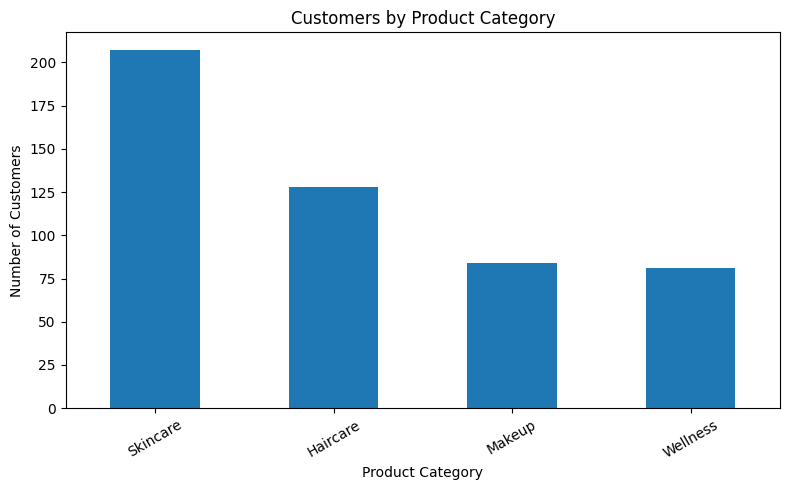

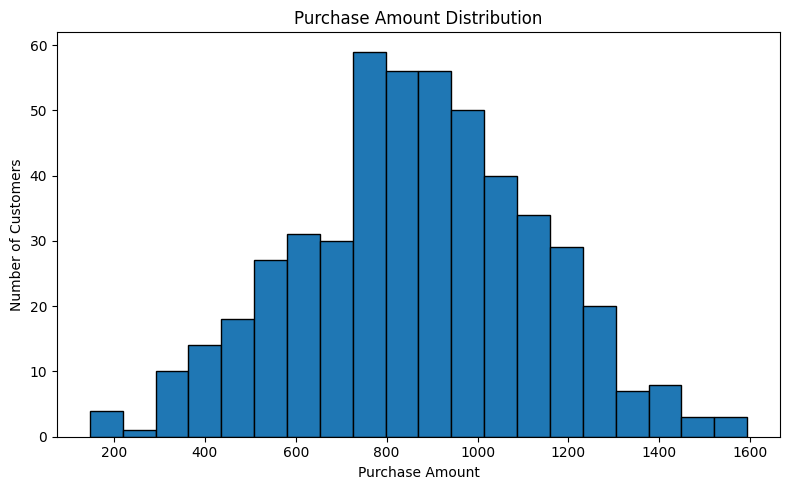

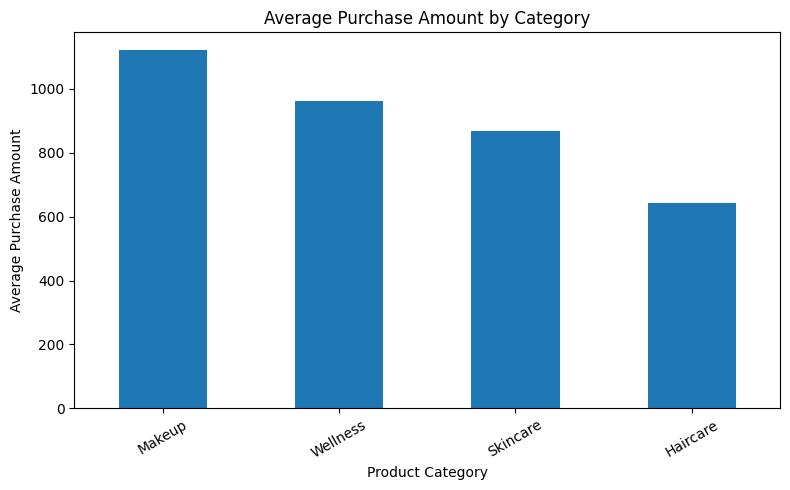

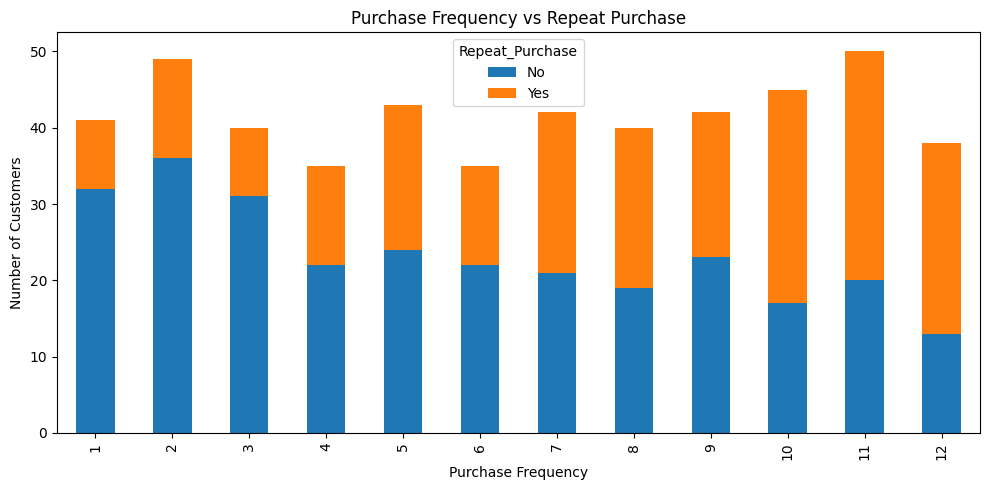

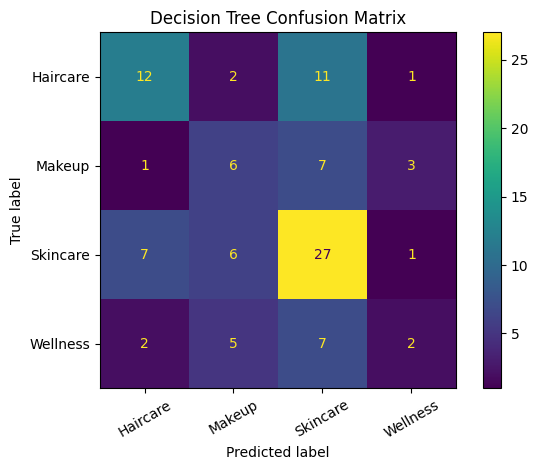

Export completed! Download website_results.zip below.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:

# EXPORT ACTUAL PROJECT RESULTS FOR YOUR WEBSITE

import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Create a folder for website assets
os.makedirs("website_results/charts", exist_ok=True)

# Chart 1: Customer count by product category
df["Product_Category"].value_counts().plot(kind="bar", figsize=(8, 5))
plt.title("Customers by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("website_results/charts/category_distribution.png", dpi=150)
plt.show()
plt.close()

# Chart 2: Purchase amount distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Purchase_Amount"], bins=20, edgecolor="black")
plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("website_results/charts/purchase_distribution.png", dpi=150)
plt.show()
plt.close()

# Chart 3: Average purchase amount by category
df.groupby("Product_Category")["Purchase_Amount"].mean().sort_values(
    ascending=False
).plot(kind="bar", figsize=(8, 5))
plt.title("Average Purchase Amount by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("website_results/charts/average_spending.png", dpi=150)
plt.show()
plt.close()

# Chart 4: Purchase frequency vs repeat purchase
pd.crosstab(
    df["Purchase_Frequency"], df["Repeat_Purchase"]
).plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Purchase Frequency vs Repeat Purchase")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("website_results/charts/repeat_purchase.png", dpi=150)
plt.show()
plt.close()

# Chart 5: Actual model confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=30
)
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.savefig("website_results/charts/confusion_matrix.png", dpi=150)
plt.show()
plt.close()

# Save actual K-Means segment summary
segment_summary = df.groupby("Customer_Segment")[
    ["Age", "Purchase_Frequency", "Purchase_Amount", "Browsing_Time"]
].mean().round(2)

segment_summary.to_csv("website_results/segment_summary.csv")

# Save actual model metrics
with open("website_results/model_results.txt", "w", encoding="utf-8") as f:
    f.write("BEAUTY & WELLNESS CUSTOMER ANALYTICS\n")
    f.write("Dataset: Synthetic demonstration data\n\n")
    f.write(f"Total customer records: {len(df)}\n")
    f.write(f"Decision Tree test accuracy: {accuracy:.2%}\n")
    f.write(
        f"Repeat purchase percentage: "
        f"{df['Repeat_Purchase'].eq('Yes').mean() * 100:.2f}%\n\n"
    )
    f.write("CLASSIFICATION REPORT\n")
    f.write(classification_report(y_test, y_pred, zero_division=0))
    f.write("\nCUSTOMER SEGMENT SUMMARY\n")
    f.write(segment_summary.to_string())

# Package everything into one ZIP file
with zipfile.ZipFile("website_results.zip", "w") as z:
    for root, dirs, files in os.walk("website_results"):
        for file in files:
            path = os.path.join(root, file)
            z.write(path, path)

print("Export completed! Download website_results.zip below.")

from google.colab import files
files.download("website_results.zip")
